# 04 — Modelling, Evaluasi, dan Konklusi
## Klasifikasi Multikelas Covertype

Notebook ini membangun dan membandingkan model klasifikasi. Bagian evaluasi dan konklusi disertakan pada notebook ini agar alur proyek sesuai panduan, yang meminta hasil evaluasi dan jawaban atas pertanyaan Business Understanding.

## 1. Import library

In [1]:
from pathlib import Path
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, classification_report,
    confusion_matrix
)

sns.set_theme(style="whitegrid")

## 2. Memuat data hasil preprocessing

Prioritasnya adalah membaca `covtype_preprocessed_split.npz` yang dihasilkan notebook 03. Jika file tersebut belum tersedia, kode akan memuat `covtype.data` dan mengulang transformasi serta split dengan parameter yang sama.

In [2]:
PREPROCESSED_PATH = Path("covtype_preprocessed_split.npz")

if PREPROCESSED_PATH.exists():
    with np.load(PREPROCESSED_PATH, allow_pickle=False) as saved:
        X_train = saved["X_train"]
        X_test = saved["X_test"]
        y_train = saved["y_train"]
        y_test = saved["y_test"]
        feature_names = saved["feature_names"].tolist()
    print("Menggunakan hasil preprocessing dari:", PREPROCESSED_PATH.resolve())
else:
    print("File hasil preprocessing tidak ditemukan. Memproses ulang dari covtype.data.")
    NUMERIC_FEATURES = [
        "Elevation", "Aspect", "Slope", "Horizontal_Distance_To_Hydrology",
        "Vertical_Distance_To_Hydrology", "Horizontal_Distance_To_Roadways",
        "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
        "Horizontal_Distance_To_Fire_Points"
    ]
    WILDERNESS_COLS = [f"Wilderness_Area{i}" for i in range(1, 5)]
    SOIL_COLS = [f"Soil_Type{i}" for i in range(1, 41)]
    TARGET_COL = "Cover_Type"
    COLUMNS = NUMERIC_FEATURES + WILDERNESS_COLS + SOIL_COLS + [TARGET_COL]

    candidates = [
        Path("covtype.data"), Path("data") / "covtype.data",
        Path("../covtype.data"), Path("../data") / "covtype.data"
    ]
    data_path = next((p for p in candidates if p.exists()), None)
    if data_path is None:
        raise FileNotFoundError(
            "Letakkan covtype_preprocessed_split.npz (hasil notebook 03) "
            "atau covtype.data di folder notebook / subfolder data/."
        )

    raw = pd.read_csv(data_path, header=None, names=COLUMNS)
    if raw.isna().sum().sum() > 0:
        raise ValueError("Ditemukan missing value; selesaikan cleaning terlebih dahulu.")
    raw = raw.drop_duplicates().copy()

    angle_rad = np.deg2rad(raw["Aspect"])
    raw["Aspect_sin"] = np.sin(angle_rad)
    raw["Aspect_cos"] = np.cos(angle_rad)
    raw = raw.drop(columns=["Aspect"])

    X = raw.drop(columns=[TARGET_COL])
    y = raw[TARGET_COL].astype(int)

    X_train_df, X_test_df, y_train_s, y_test_s = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )
    selector = VarianceThreshold(threshold=0.0)
    X_train = selector.fit_transform(X_train_df)
    X_test = selector.transform(X_test_df)
    y_train = y_train_s.to_numpy()
    y_test = y_test_s.to_numpy()
    feature_names = X_train_df.columns[selector.get_support()].tolist()

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)
print("Jumlah fitur  :", len(feature_names))
print("Kelas train   :", np.unique(y_train))
print("Kelas test    :", np.unique(y_test))

Menggunakan hasil preprocessing dari: C:\Users\parsey\Downloads\Covertype_4_Phase_Notebooks\covtype_preprocessed_split.npz
Ukuran X_train: (464809, 55)
Ukuran X_test : (116203, 55)
Jumlah fitur  : 55
Kelas train   : [1 2 3 4 5 6 7]
Kelas test    : [1 2 3 4 5 6 7]


## 3. Menetapkan baseline dan model pembanding

Model yang dibandingkan:

1. **Dummy Classifier (most frequent):** baseline sederhana yang selalu memprediksi kelas mayoritas. Ini membantu menunjukkan mengapa accuracy saja dapat menyesatkan.
2. **Decision Tree:** model pohon keputusan yang relatif mudah diinterpretasikan.
3. **Random Forest:** ensemble beberapa pohon keputusan. `class_weight="balanced_subsample"` membantu memberi bobot lebih besar pada kelas yang lebih jarang pada setiap bootstrap sample.

Parameter dibatasi agar eksperimen pada dataset besar tetap lebih terkelola. Waktu training bergantung pada spesifikasi komputer. Jika Random Forest terlalu lama, jumlah pohon dapat diturunkan untuk eksperimen awal, lalu dicatat sebagai perubahan konfigurasi.

In [3]:
models = {
    "Dummy (majority baseline)": DummyClassifier(strategy="most_frequent"),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=25,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=25,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42,
        max_samples=0.8
    )
}

## 4. Training model

Semua model dilatih menggunakan data training yang sama. Data test tidak digunakan pada proses pelatihan.

In [4]:
trained_models = {}
training_times = {}

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start

    trained_models[name] = model
    training_times[name] = elapsed
    print(f"{name}: selesai dalam {elapsed:.2f} detik")

Dummy (majority baseline): selesai dalam 0.02 detik
Decision Tree: selesai dalam 4.52 detik
Random Forest: selesai dalam 10.46 detik


## 5. Evaluasi dan perbandingan model

Macro-F1 menjadi metrik utama karena menghitung F1 setiap kelas dengan bobot sama. Balanced accuracy dan recall macro juga membantu menilai kemampuan model pada kelas minoritas.

In [5]:
CLASS_NAMES = [
    "Spruce/Fir", "Lodgepole Pine", "Ponderosa Pine",
    "Cottonwood/Willow", "Aspen", "Douglas-fir", "Krummholz"
]
LABELS = [1, 2, 3, 4, 5, 6, 7]

results = []
predictions = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision Macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall Macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 Macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 Weighted": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "Training Time (s)": training_times[name]
    })

results_df = pd.DataFrame(results).sort_values("F1 Macro", ascending=False)
display(results_df.round(4))

,Model,Accuracy,Balanced Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted,Training Time (s)
2,Random Forest,0.9309,0.9234,0.8788,0.9234,0.8996,0.9312,10.4590
1,Decision Tree,0.9019,0.9081,0.7889,0.9081,0.8353,0.9046,4.5223
0,Dummy (majority baseline),0.4876,0.1429,0.0697,0.1429,0.0937,0.3197,0.0153


### Interpretasi perbandingan

Bandingkan hasil setiap model, terutama:

- Apakah model kompleks meningkatkan Macro-F1 dibanding baseline?
- Apakah accuracy jauh lebih tinggi daripada Macro-F1? Jika ya, hal tersebut dapat menunjukkan bahwa kelas mayoritas lebih mudah mendominasi hasil.
- Apakah model dengan Macro-F1 terbaik juga memiliki balanced accuracy yang baik?
- Pertimbangkan waktu training sebagai aspek praktis, bukan sebagai pengganti kualitas prediksi.

## 6. Memilih model terbaik dan classification report

Model terbaik pada eksperimen ini dipilih berdasarkan Macro-F1 pada data test. Keputusan akhir tetap perlu mempertimbangkan recall kelas yang paling penting bagi konteks penggunaan.

In [6]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
y_pred_best = predictions[best_model_name]

print("Model terbaik berdasarkan Macro-F1:", best_model_name)
print(classification_report(
    y_test,
    y_pred_best,
    labels=LABELS,
    target_names=CLASS_NAMES,
    zero_division=0
))

Model terbaik berdasarkan Macro-F1: Random Forest
                   precision    recall  f1-score   support

       Spruce/Fir       0.94      0.92      0.93     42368
   Lodgepole Pine       0.94      0.94      0.94     56661
   Ponderosa Pine       0.91      0.94      0.93      7151
Cottonwood/Willow       0.84      0.90      0.87       549
            Aspen       0.74      0.89      0.81      1899
      Douglas-fir       0.84      0.91      0.87      3473
        Krummholz       0.94      0.96      0.95      4102

         accuracy                           0.93    116203
        macro avg       0.88      0.92      0.90    116203
     weighted avg       0.93      0.93      0.93    116203



## 7. Confusion matrix

Confusion matrix menunjukkan kelas aktual pada baris dan prediksi pada kolom. Versi normalisasi per baris memudahkan pembacaan recall setiap kelas.

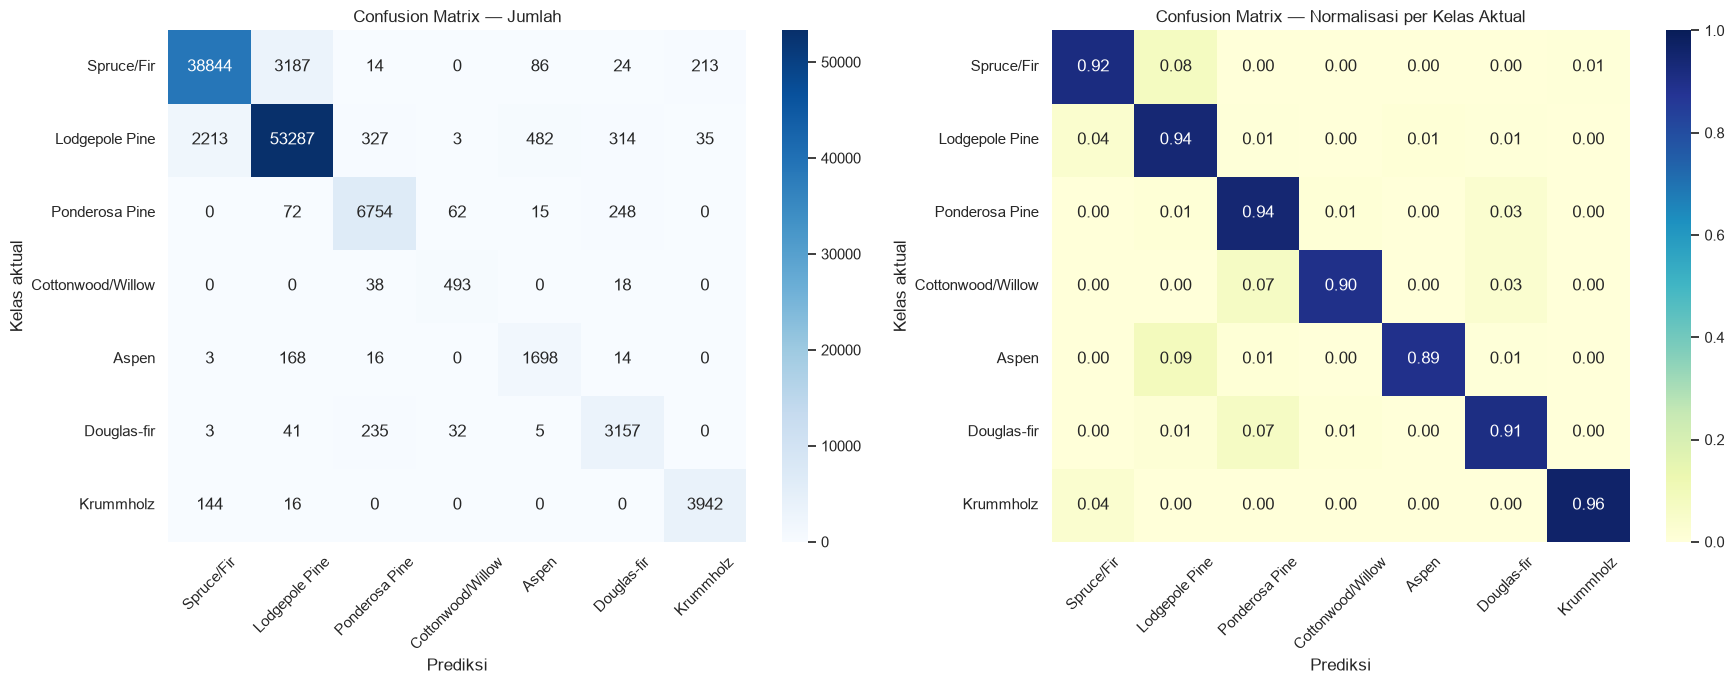

In [7]:
cm = confusion_matrix(y_test, y_pred_best, labels=LABELS)
cm_normalized = confusion_matrix(
    y_test, y_pred_best, labels=LABELS, normalize="true"
)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0]
)
axes[0].set_title("Confusion Matrix — Jumlah")
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Kelas aktual")
axes[0].tick_params(axis="x", rotation=45)
axes[0].tick_params(axis="y", rotation=0)

sns.heatmap(
    cm_normalized, annot=True, fmt=".2f", cmap="YlGnBu",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1],
    vmin=0, vmax=1
)
axes[1].set_title("Confusion Matrix — Normalisasi per Kelas Aktual")
axes[1].set_xlabel("Prediksi")
axes[1].set_ylabel("Kelas aktual")
axes[1].tick_params(axis="x", rotation=45)
axes[1].tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

In [8]:
cm_offdiag = cm.copy()
np.fill_diagonal(cm_offdiag, 0)
row_idx, col_idx = np.unravel_index(np.argmax(cm_offdiag), cm_offdiag.shape)

print(
    "Pasangan kesalahan terbanyak:",
    f"kelas aktual {LABELS[row_idx]} ({CLASS_NAMES[row_idx]})",
    "diprediksi sebagai",
    f"kelas {LABELS[col_idx]} ({CLASS_NAMES[col_idx]})",
    f"sebanyak {cm_offdiag[row_idx, col_idx]:,} observasi."
)

Pasangan kesalahan terbanyak: kelas aktual 1 (Spruce/Fir) diprediksi sebagai kelas 2 (Lodgepole Pine) sebanyak 3,187 observasi.


**Interpretasi:** identifikasi kelas dengan recall terendah dan pasangan kelas yang paling sering tertukar. Jelaskan dampak kesalahan tersebut terhadap tujuan penggunaan model.

## 8. Feature importance

Feature importance tersedia pada model pohon. Nilai ini menunjukkan kontribusi relatif fitur dalam pemisahan pada model, tetapi bukan bukti hubungan sebab-akibat.

,Feature,Importance
0,Elevation,0.238465
4,Horizontal_Distance_To_Roadways,0.105936
8,Horizontal_Distance_To_Fire_Points,0.080308
2,Horizontal_Distance_To_Hydrology,0.057754
12,Wilderness_Area4,0.050393
3,Vertical_Distance_To_Hydrology,0.047418
5,Hillshade_9am,0.037870
54,Aspect_cos,0.036106
7,Hillshade_3pm,0.030607
6,Hillshade_Noon,0.029379


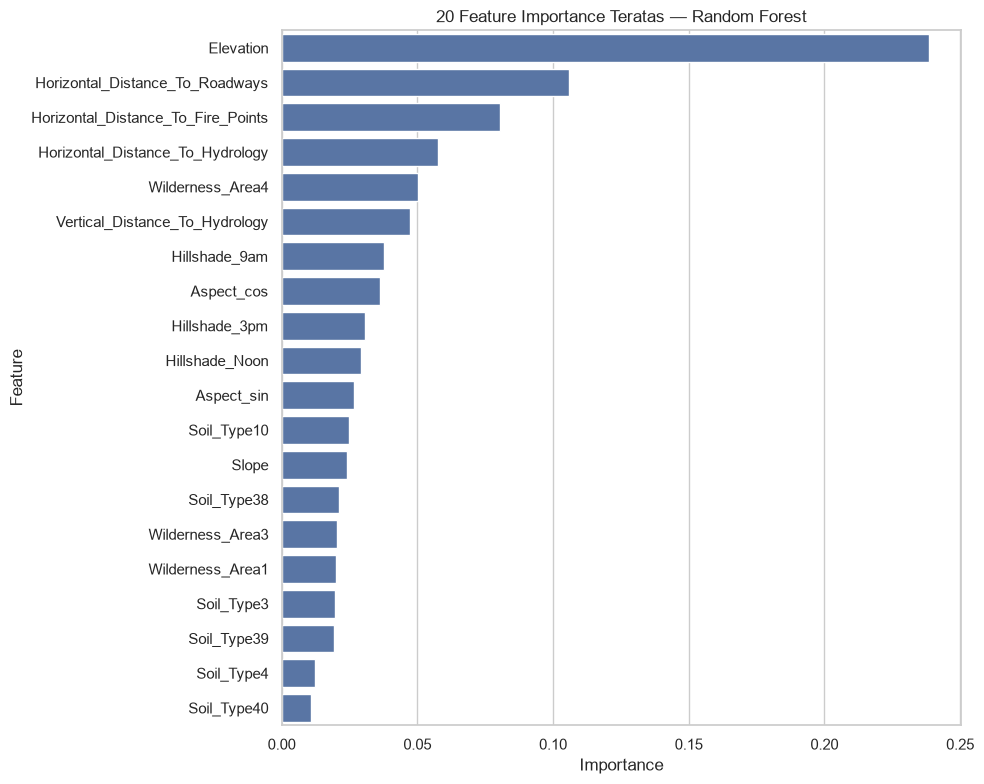

In [9]:
if hasattr(best_model, "feature_importances_"):
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": best_model.feature_importances_
    }).sort_values("Importance", ascending=False)

    display(importance_df.head(20))

    plt.figure(figsize=(10, 8))
    sns.barplot(
        data=importance_df.head(20),
        x="Importance", y="Feature"
    )
    plt.title(f"20 Feature Importance Teratas — {best_model_name}")
    plt.tight_layout()
    plt.show()
else:
    print("Model terpilih tidak menyediakan feature_importances_.")

**Interpretasi:** jelaskan fitur yang paling berpengaruh menurut model. Ingat bahwa feature importance dapat bias terhadap karakteristik fitur dan tidak menjelaskan arah pengaruh secara kausal.

## 9. Konklusi proyek

Panduan proyek meminta konklusi menjawab pertanyaan Business Understanding, menerjemahkan metrik ke makna praktis, menjelaskan keputusan, dan menyampaikan keterbatasan. Gunakan angka aktual dari hasil notebook.

In [10]:
best_row = results_df.iloc[0]
worst_class_idx = int(np.argmin([
    recall_score(y_test, y_pred_best, labels=[label], average="macro", zero_division=0)
    for label in LABELS
]))
per_class_recall = cm.diagonal() / np.maximum(cm.sum(axis=1), 1)
lowest_recall_class = LABELS[int(np.argmin(per_class_recall))]

print("RINGKASAN HASIL")
print("================")
print("Model terbaik:", best_model_name)
print(f"Accuracy       : {best_row['Accuracy']:.4f}")
print(f"Balanced Acc.  : {best_row['Balanced Accuracy']:.4f}")
print(f"Macro-F1       : {best_row['F1 Macro']:.4f}")
print(f"Weighted F1    : {best_row['F1 Weighted']:.4f}")
print(f"Recall terendah: kelas {lowest_recall_class} "
      f"({CLASS_NAMES[lowest_recall_class - 1]}) = "
      f"{per_class_recall[lowest_recall_class - 1]:.4f}")

RINGKASAN HASIL
Model terbaik: Random Forest
Accuracy       : 0.9309
Balanced Acc.  : 0.9234
Macro-F1       : 0.8996
Weighted F1    : 0.9312
Recall terendah: kelas 5 (Aspen) = 0.8942


### Poin konklusi yang harus ditulis

1. **Jawaban rumusan masalah:** apakah fitur kartografis dapat digunakan untuk memprediksi jenis tutupan hutan pada dataset ini?
2. **Pemilihan model:** jelaskan model terbaik berdasarkan Macro-F1 dan bandingkan dengan baseline serta model pembanding.
3. **Makna metrik:** terjemahkan Macro-F1, accuracy, balanced accuracy, dan recall kelas ke bahasa yang mudah dipahami.
4. **Kelas sulit:** jelaskan kelas dengan recall terendah dan kemungkinan penyebabnya berdasarkan EDA/confusion matrix.
5. **Keputusan preprocessing:** rangkum alasan mempertahankan outlier, transformasi Aspect, dan penggunaan class weighting.
6. **Keterbatasan:** cakupan geografis dataset terbatas, tidak ada koordinat untuk validasi spasial, kemungkinan autokorelasi spasial, distribusi kelas tidak seimbang, serta data berasal dari tahun 1998.
7. **Pengembangan lanjutan:** pertimbangkan validasi berbasis wilayah jika koordinat tersedia, penalaan hyperparameter, dan evaluasi yang lebih mendalam pada kelas minoritas.

**Penting:** jangan mengklaim model berlaku universal untuk seluruh hutan. Hasil hanya mendukung kesimpulan pada data dan prosedur evaluasi yang digunakan.

## 10. Referensi

1. Blackard, J. A. (1998). *Covertype* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C50K5N
2. UCI Machine Learning Repository. *Covertype*. https://archive.ics.uci.edu/dataset/31/covertype
3. Panduan Proyek Akhir Praktikum Data Science 2026/2027, Program Studi Informatika, UPN “Veteran” Yogyakarta.